# Что слушают в Москве и Петербурге

**Учебный проект Яндекс Практикума · анализ данных на pandas**

Правда ли, что Москва начинает рабочую неделю активнее Петербурга, а в Петербурге чаще выбирают русский рэп? Я сравнил записи Яндекс Музыки сначала по дням, затем по жанрам. Один старт трека считаю одним прослушиванием. Длительность трека и время, которое человек действительно провёл за прослушиванием, в выгрузке не указаны.

| Вопрос | Что получилось |
| --- | --- |
| В какие дни больше слушают? | На среду пришлось 25,9% стартов в Москве и 37,8% в Петербурге. Из трёх дней выборки среда оказалась самой тихой в Москве и самой активной в Петербурге. |
| Различаются ли лидеры утром и вечером? | Среди известных жанров поп занял первое место в обоих городах и утром в понедельник, и вечером в пятницу. |
| Что предпочитают в Петербурге? | Поп набрал 13,3% стартов с известным жанром, русский рэп — 3,1%. В Москве тоже лидирует поп. |

[Данные](#data) · [Дни недели](#days) · [Утро и вечер](#windows) · [Жанры двух городов](#genres) · [Вывод](#result)

<a id="data"></a>
## 1. Что записано в журнале

В каждой строке есть идентификатор слушателя, название трека, исполнитель, жанр, город, время начала и день недели. Календарной даты нет. Для повторного запуска нужен исходный файл курса `yandex_music_project.csv` рядом с ноутбуком или в каталоге `/datasets`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

filename = 'yandex_music_project.csv'
paths = [Path(filename), Path('data') / filename, Path('/datasets') / filename]
data_path = next((path for path in paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f'Положите {filename} рядом с ноутбуком.')

raw = pd.read_csv(data_path)
raw.columns = raw.columns.str.strip().str.lower()
raw = raw.rename(columns={'userid': 'user_id'})
fields = {
    'user_id': 'Идентификатор слушателя', 'track': 'Название трека',
    'artist': 'Исполнитель', 'genre': 'Жанр', 'city': 'Город',
    'time': 'Время старта', 'day': 'День недели',
}
assert set(raw.columns) == set(fields)
audit = pd.DataFrame({'Содержание': pd.Series(fields), 'Тип при чтении': raw.dtypes.astype(str),
                      'Пропуски': raw.isna().sum()})
display(audit)
print(f'Строк до очистки: {len(raw):,}. Полных повторов: {raw.duplicated().sum():,}.'.replace(',', ' '))

,Содержание,Тип при чтении,Пропуски
user_id,Идентификатор слушателя,str,0
track,Название трека,str,1231
artist,Исполнитель,str,7203
genre,Жанр,str,1198
city,Город,str,0
time,Время старта,str,0
day,День недели,str,0


Строк до очистки: 65 079. Полных повторов: 3 826.


У 1 231 записи отсутствует название трека, у 7 203 — исполнитель, у 1 198 — жанр. Эти пропуски могут возникать, если в карточку трека не внесли все сведения. Сам старт от этого не исчезает. Для сравнения активности сохраню такие события, а при сравнении жанров покажу, сколько записей удалось классифицировать.

Полные повторы уберу по всем семи полям. Без уникального номера события нельзя выяснить происхождение каждого повтора. Совпадения только по слушателю или названию трека сохраняю: одну песню можно включить несколько раз.

In [2]:
music = raw.drop_duplicates().reset_index(drop=True).copy()
music['genre'] = music['genre'].astype('string').str.strip().str.lower()
hip_labels = ['hip', 'hop', 'hip-hop', 'hiphop']
print('Метки хип-хопа до объединения:')
display(music.loc[music['genre'].isin(hip_labels), 'genre'].value_counts().rename('Стартов').to_frame())
music['genre'] = music['genre'].replace(dict.fromkeys(hip_labels, 'hiphop'))

cities = ['Moscow', 'Saint-Petersburg']
city_ru = {'Moscow': 'Москва', 'Saint-Petersburg': 'Петербург'}
days = ['Monday', 'Wednesday', 'Friday']
day_ru = {'Monday': 'Понедельник', 'Wednesday': 'Среда', 'Friday': 'Пятница'}
assert set(music['city'].dropna()) == set(cities) and set(music['day'].dropna()) == set(days)
assert music[['city', 'day', 'user_id', 'time']].notna().all().all()
music['start_time'] = pd.to_timedelta(music['time'])
assert music['start_time'].between(pd.Timedelta(0), pd.Timedelta(days=1), inclusive='left').all()

coverage = music.groupby('city').agg(
    starts=('user_id', 'size'), known=('genre', 'count'), listeners=('user_id', 'nunique'))
coverage['missing'] = coverage['starts'] - coverage['known']
coverage['known_pct'] = (100 * coverage['known'] / coverage['starts']).round(1)
display(coverage.rename(index=city_ru, columns={'starts': 'Стартов', 'known': 'С жанром',
                 'listeners': 'Уникальных слушателей', 'missing': 'Без жанра', 'known_pct': 'С жанром, %'}))
print(f"После очистки: {len(music):,} стартов; время от {music['time'].min()} до {music['time'].max()}."
      .replace(',', ' '))

Метки хип-хопа до объединения:


,Стартов
genre,
hip,2975
hiphop,79
hip-hop,1
hop,1


,Стартов,С жанром,Уникальных слушателей,Без жанра,"С жанром, %"
city,,,,,
Москва,42741,41892,29358,849,98.0
Петербург,18512,18234,12423,278,98.5


После очистки: 61 253 стартов; время от 08:00:00 до 22:00:59.


После очистки осталось 61 253 старта. Жанр неизвестен у 849 московских и 278 петербургских записей. Четыре варианта обозначения хип-хопа объединены под меткой `hiphop`. Для редких неоднозначных меток, например `ïîï`, в файле нет расшифровки. Их сохранил как в источнике. В третьей гипотезе русский рэп соответствует отдельной метке `rusrap`.

<a id="days"></a>
## 2. В какие дни слушают больше

**Первая гипотеза.** Активность меняется по дням недели, и у каждого города свой ритм. Московских записей больше, поэтому для каждого города посчитаю долю его стартов, пришедшуюся на понедельник, среду и пятницу. Дополнительно сравню число разных слушателей, чтобы проверить, повторяется ли картина у аудитории.

In [3]:
keys = ['city', 'day']
day_stats = (music.groupby(keys)
             .agg(starts=('user_id', 'size'), listeners=('user_id', 'nunique'))
             .reindex(pd.MultiIndex.from_product([cities, days], names=keys)))
day_stats['share'] = day_stats['starts'] / day_stats.groupby(level='city')['starts'].transform('sum')
day_stats['per_listener'] = day_stats['starts'] / day_stats['listeners']
day_view = day_stats.reset_index()
day_view['city'] = day_view['city'].map(city_ru)
day_view['day'] = day_view['day'].map(day_ru)
day_view['share'] = (day_view['share'] * 100).round(1)
display(day_view.rename(columns={'city': 'Город', 'day': 'День', 'starts': 'Стартов',
                        'listeners': 'Слушателей', 'share': 'Доля в городе, %',
                        'per_listener': 'Стартов на слушателя'}).round(2).set_index(['Город', 'День']))

Стартов  Слушателей  Доля в городе, %  \
Город     День                                                 
Москва    Понедельник    15740       11904              36.8   
          Среда          11056        8388              25.9   
          Пятница        15945       12145              37.3   
Петербург Понедельник     5614        4248              30.3   
          Среда           7003        5228              37.8   
          Пятница         5895        4495              31.8   

                       Стартов на слушателя  
Город     День                               
Москва    Понедельник                  1.32  
          Среда                        1.32  
          Пятница                      1.31  
Петербург Понедельник                  1.32  
          Среда                        1.34  
          Пятница                      1.31

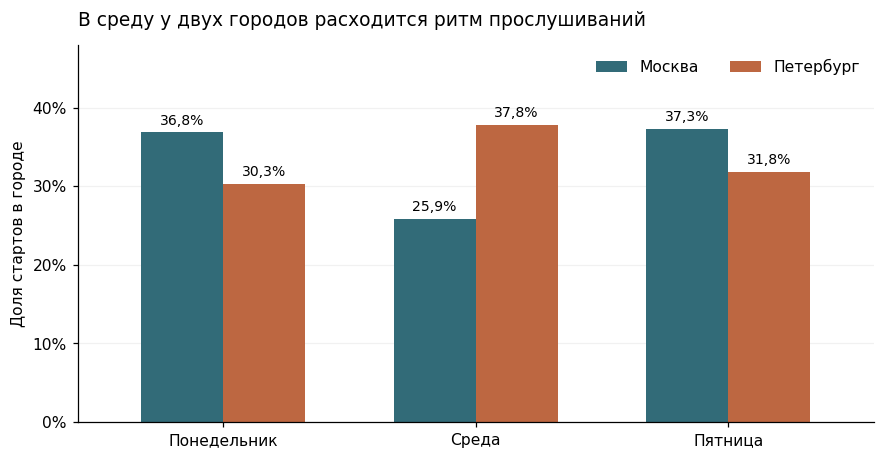

In [4]:
palette = ['#326b78', '#bd6741']
plt.rcParams.update({'figure.dpi': 112, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlelocation': 'left', 'axes.titlepad': 12})
daily = day_stats['share'].unstack(level='city').reindex(index=days, columns=cities)
ax = daily.rename(index=day_ru, columns=city_ru).plot.bar(figsize=(8, 4.2), width=.65,
                                                          color=palette, rot=0)
ax.set(title='В среду у двух городов расходится ритм прослушиваний',
       ylabel='Доля стартов в городе', xlabel='', ylim=(0, .48))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title='', frameon=False, loc='upper right', ncol=2)
for group in ax.containers:
    ax.bar_label(group, labels=[f'{v.get_height():.1%}'.replace('.', ',') for v in group],
                 padding=3, fontsize=9)
ax.grid(axis='y', alpha=.17)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

В Москве в среду зафиксировано 11 056 стартов, меньше, чем в понедельник и пятницу. В Петербурге среда на первом месте с 7 003 стартами. У числа активных слушателей тот же рисунок: в среду московская аудитория наименьшая из трёх дней (8 388 человек), петербургская — наибольшая (5 228). При этом на одного активного слушателя приходится примерно 1,3 старта во всех шести группах.

Для наблюдаемых дней первая гипотеза поддерживается. Сколько календарных понедельников, сред и пятниц попало в выгрузку, неизвестно, поэтому переносить это соотношение на обычную неделю пока рано.

<a id="windows"></a>
## 3. Что ставят в понедельник утром и в пятницу вечером

**Вторая гипотеза.** В одно и то же время в городах лидируют разные жанры. Утром считаю интервал с 07:00 до 11:00, вечером — с 17:00 до 23:00. Левая граница входит в интервал, правая открывает следующий. В журнале самая ранняя запись начинается в 08:00, а самая поздняя — в 22:00:59. Сравнение относится к зафиксированной части этих интервалов.

In [5]:
def genre_ranking(events):
    counts = (events.groupby('genre').size().rename('starts').reset_index()
              .sort_values(['starts', 'genre'], ascending=[False, True]).reset_index(drop=True))
    counts['share'] = counts['starts'] / counts['starts'].sum()
    counts['rank'] = counts['starts'].rank(method='min', ascending=False).astype(int)
    return counts

windows = [('Пн, утро', 'Monday', '07:00:00', '11:00:00'),
           ('Пт, вечер', 'Friday', '17:00:00', '23:00:00')]
window_tops = {}
window_totals = []
for label, day, begin, end in windows:
    in_window = music['day'].eq(day) & music['start_time'].between(
        pd.Timedelta(begin), pd.Timedelta(end), inclusive='left')
    for city in cities:
        events = music.loc[in_window & music['city'].eq(city)]
        ranking = genre_ranking(events).head(10)
        window_tops[(label, city)] = ranking
        window_totals.append([label, city_ru[city], len(events), events['genre'].count(),
                               events['genre'].isna().sum()])
totals = pd.DataFrame(window_totals, columns=['Интервал', 'Город', 'Стартов', 'С жанром', 'Без жанра'])
display(totals.set_index(['Интервал', 'Город']))

Стартов  С жанром  Без жанра
Интервал  Город                                  
Пн, утро  Москва        5258      5097        161
          Петербург     1605      1587         18
Пт, вечер Москва        5294      5184        110
          Петербург     2066      2019         47

In [6]:
# Для равного числа стартов показываю одинаковый ранг и упорядочиваю названия по алфавиту.
for label, *_ in windows:
    comparison = {}
    for city in cities:
        top = window_tops[(label, city)].copy()
        top['share'] = (100 * top['share']).round(1)
        comparison[city_ru[city]] = top[['rank', 'genre', 'starts', 'share']].rename(
            columns={'rank': 'Место', 'genre': 'Жанр', 'starts': 'Стартов', 'share': 'Доля, %'})
    print(f'{label} — доли среди записей с известным жанром')
    display(pd.concat(comparison, axis=1).style.hide(axis='index').format(precision=1, decimal=','))
    common = set(window_tops[(label, cities[0])]['genre']) & set(window_tops[(label, cities[1])]['genre'])
    print(f'Общих жанров в десятках: {len(common)}.')

Пн, утро — доли среди записей с известным жанром


Общих жанров в десятках: 9.
Пт, вечер — доли среди записей с известным жанром


Общих жанров в десятках: 9.


В понедельник утром поп первый в обоих городах. За ним идёт танцевальная музыка. Вечером в пятницу поп снова впереди, но второе место выглядит иначе: в Москве это рок (517 стартов), в Петербурге рок и электроника делят его (по 216). В каждом из двух интервалов девять жанров из первой десятки совпадают между городами.

Среди записей с известным жанром гипотеза о разных лидерах не подтвердилась. Точный порядок вблизи вершины чувствителен к пропускам: в пятницу вечером в Петербурге у 47 стартов нет жанра, а разрыв между попом и второй строкой равен 40. Присвоить этим записям жанр по таблице нельзя.

<a id="genres"></a>
## 4. Правда ли, что Петербург выбирает русский рэп

**Третья гипотеза.** В Москве самый популярный жанр — поп, а в Петербурге — русский рэп. Для каждого города сравню число стартов за все три дня и долю жанра среди классифицированных записей.

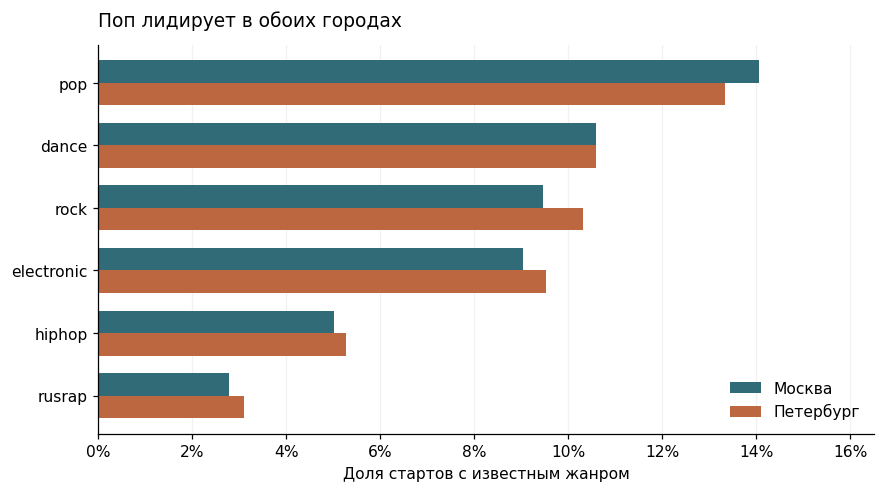

In [7]:
rankings = {city: genre_ranking(music.loc[music['city'].eq(city)]) for city in cities}
full_top = {}
for city, ranking in rankings.items():
    top = ranking.head(10).set_index('rank').copy()
    top['share'] = (100 * top['share']).round(1)
    full_top[city_ru[city]] = top.rename(columns={'genre': 'Жанр', 'starts': 'Стартов', 'share': 'Доля, %'})
display(pd.concat(full_top, axis=1).rename_axis('Место').style.format(precision=1, decimal=','))

selected = ['pop', 'dance', 'rock', 'electronic', 'hiphop', 'rusrap']
shares = pd.DataFrame({city_ru[c]: ranking.set_index('genre')['share'] for c, ranking in rankings.items()})
ax = shares.loc[selected].plot.barh(figsize=(8, 4.5), width=.72, color=palette)
ax.invert_yaxis()
ax.set(xlabel='Доля стартов с известным жанром', ylabel='', xlim=(0, .165),
       title='Поп лидирует в обоих городах')
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title='', loc='lower right', frameon=False)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=.17)
plt.tight_layout()
plt.show()

Первая пятёрка в обоих городах совпадает даже по порядку: поп, танцевальная музыка, рок, электроника и хип-хоп. В Москве у попа 5 892 старта из 41 892 с известным жанром (14,1%), в Петербурге — 2 431 из 18 234 (13,3%).

У русского рэпа доля в Петербурге действительно немного выше: 3,1% против 2,8% в Москве. При этом в Петербурге он на восьмом месте, в Москве — на десятом. Даже если все 278 петербургских стартов без жанра отнести к русскому рэпу, у него будет 842 старта против 2 431 у попа. Гипотеза о разных любимых жанрах в целом не подтверждается.

<a id="result"></a>
## 5. Что это меняет для музыкальной подборки

Я бы начал с общего жанрового ядра для двух городов. Для отдельной рэп-подборки в Петербурге можно проверить спрос, но делать её главной на основании этой выгрузки я бы не стал. Городской график публикаций выглядит более перспективной гипотезой: в выборке интересен контраст среды с понедельником и пятницей.

Перед изменением расписания я бы взял несколько полных календарных недель и сравнил одинаковые часы по всем семи дням. В журнале стартов также не видно, что сервис предложил слушателю и сколько секунд он слушал. Данные о показах и длительности помогли бы отличить доступность подборки от осознанного выбора трека.